In [2]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP8\day8"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP8\day8\complex_system
number of cells: 125


In [3]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,notes,manipulation,stimuli,basepath
0,presleep_230706_101325,0.0000,7747.95515,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
1,T_long_230706_123014,7747.9552,10138.29755,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
2,midsleep_230706_132205,10138.2976,16915.05275,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
3,T_long2_230706_151914,16915.0528,19030.14395,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
4,postsleep_230706_155635,19030.1440,26253.07515,sleep,NaN,postsleep animal eye was not fully open,NaN,NaN,W:\data\PPP\PPP8\day8


In [4]:
import os, re, numpy as np, pandas as pd
import glob
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Loads all sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved.mat", f"*_{region}_D2_time.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day8_CA1_D2_time_resolved.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 125, 'total_spikes': 9525080}
   State 0: NREM - requested points=5124, actual used=5124
     Time range: 367.0 to 26220.0
     D2 range: 0.0311 to 0.2262
     D2_ERR: missing → filled with NaN
   State 1: REM - requested points=47, actual used=47
     Time range: 24045.0 to 25855.0
     D2 range: 0.0444 to 0.0944
     D2_ERR: missing → filled with NaN
   State 2: WAKE - requested points=5140, actual used=5140
     Time range: 21.0 to 25297.0
     D2 range: 0.0152 to 0.2642
     D2_ERR: missing → filled with NaN

✅ Complete timeline created:
📊 Total data points: 10311
📊 Time range: 21.0 to 26220.0
📊 Duration: 26199.0 seconds
📊 State distribution:
state
WAKE    5140
NREM    5124
REM       47
Name: count, dtype: int64



In [5]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,notes,manipulation,stimuli,basepath
0,presleep_230706_101325,0.0000,7747.95515,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
1,T_long_230706_123014,7747.9552,10138.29755,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
2,midsleep_230706_132205,10138.2976,16915.05275,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
3,T_long2_230706_151914,16915.0528,19030.14395,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
4,postsleep_230706_155635,19030.1440,26253.07515,sleep,NaN,postsleep animal eye was not fully open,NaN,NaN,W:\data\PPP\PPP8\day8


In [6]:
sleep_epochs

<EpochArray at 0x11ec6c79e10: 5 epochs> of length 7:17:33:074 hours

In [7]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.104129,NaN,WAKE
1,23.0,0.104855,NaN,WAKE
2,25.0,0.108535,NaN,WAKE
3,27.0,0.116427,NaN,WAKE
4,29.0,0.121024,NaN,WAKE
...,...,...,...,...
10306,26212.0,0.054815,NaN,NREM
10307,26214.0,0.058221,NaN,NREM
10308,26216.0,0.063023,NaN,NREM
10309,26218.0,0.058639,NaN,NREM


In [8]:
# sleep_epochs = epoch_df.loc[
#     epoch_df["name"].str.contains("midsleep", case=False),
#     ["startTime", "stopTime"]
# ].values
# import numpy as np

# t = ca1_complete_df["center_s"].values

# mask = np.zeros(len(t), dtype=bool)
# for start, stop in sleep_epochs:
#     mask |= (t >= start) & (t <= stop)

# ca1_complete_df = ca1_complete_df.loc[mask].reset_index(drop=True)

In [9]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.104129,NaN,WAKE
1,23.0,0.104855,NaN,WAKE
2,25.0,0.108535,NaN,WAKE
3,27.0,0.116427,NaN,WAKE
4,29.0,0.121024,NaN,WAKE
...,...,...,...,...
10306,26212.0,0.054815,NaN,NREM
10307,26214.0,0.058221,NaN,NREM
10308,26216.0,0.063023,NaN,NREM
10309,26218.0,0.058639,NaN,NREM


In [10]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in spike_times if st is not None and len(st) > 0])
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in arr if st is not None and len(st) > 0])
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        raise ValueError("No valid spike times found after flattening.")
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]

In [11]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Compute MUA firing rate with 0.04 second bins
time_bins, firing_rate = bin_spikes(spike_times, bin_size=0.04)

Computing MUA firing rate from spike times...


In [12]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df          # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df         # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
tb = np.asarray(time_bins, float).ravel()
fr = np.asarray(firing_rate, float).ravel()

if tb.size == fr.size + 1:            # looks like edges -> make centers
    t = 0.5 * (tb[:-1] + tb[1:])
elif tb.size == fr.size:               # already centers
    t = tb
else:
    raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

# 2) Clean + sort
ok = np.isfinite(t) & np.isfinite(fr)
t, fr = t[ok], fr[ok]
ordr = np.argsort(t)
t, fr = t[ordr], fr[ordr]

# 3) 30 s centered moving average AND standard deviation of MUA
dt = float(np.median(np.diff(t)))
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

# Use pandas rolling for a centered window
fr_series = pd.Series(fr, index=pd.Index(t, name="t"))
roller = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4))

fr_mean_30s = roller.mean().to_numpy()
fr_std_30s = roller.std().to_numpy()  # Calculate Std Dev on the same window

# 4) Interpolate both metrics onto the D² centers
centers = np.asarray(ca1_complete_df["center_s"], float)

mua_mean_at_centers = np.interp(centers, t, fr_mean_30s, left=np.nan, right=np.nan)
mua_std_at_centers = np.interp(centers, t, fr_std_30s, left=np.nan, right=np.nan)

# 5) Save to dataframe
ca1_complete_df["MUA"] = mua_mean_at_centers
ca1_complete_df["MUA_std"] = mua_std_at_centers


In [13]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA,MUA_std
0,21.0,0.104129,NaN,WAKE,321.616667,251.916491
1,23.0,0.104855,NaN,WAKE,324.033333,251.082087
2,25.0,0.108535,NaN,WAKE,324.266667,252.488031
3,27.0,0.116427,NaN,WAKE,323.900000,265.191848
4,29.0,0.121024,NaN,WAKE,322.600000,264.319417
...,...,...,...,...,...,...
10306,26212.0,0.054815,NaN,NREM,319.833333,346.825368
10307,26214.0,0.058221,NaN,NREM,324.850000,345.809204
10308,26216.0,0.063023,NaN,NREM,347.033333,364.550019
10309,26218.0,0.058639,NaN,NREM,336.583333,362.877570


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Inputs assumed to exist ---
# E_spikes: array/list of excitatory spike times
# I_spikes: array/list of inhibitory spike times
# ca1_complete_df: has a 'center_s' column

import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# E_spikes: array of Excitatory spike times
# I_spikes: array of Inhibitory spike times
# ca1_complete_df: has a 'center_s' column
# bin_spikes(spikes, bin_size, t_start=None, t_end=None): defined in the notebook

print("Computing E/I Ratio (30s smoothed) using bin_spikes...")
print("="*50)


# 2. Bin spikes for both populations
# Note: passing t_start/t_end ensures alignment
time_bins, fr_E = bin_spikes(E_spikes, bin_size=0.04)
_,         fr_I = bin_spikes(I_spikes, bin_size=0.04)

# 3. Clean and prepare for smoothing
# Use the centers of the bins
if len(time_bins) == len(fr_E) + 1:
    t_centers = 0.5 * (time_bins[:-1] + time_bins[1:])
else:
    t_centers = time_bins

# Ensure matching lengths (in case bin_spikes returns slight mismatches due to floating point)
n_bins = min(len(fr_E), len(fr_I), len(t_centers))
t_centers = t_centers[:n_bins]
fr_E = fr_E[:n_bins]
fr_I = fr_I[:n_bins]

# 4. Smooth E and I separately (30s window)
# Smoothing *before* division is critical to avoid instability from low firing rates
dt = 0.04
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

temp_df = pd.DataFrame({
    'fr_E': fr_E,
    'fr_I': fr_I
}, index=t_centers)

# Centered rolling mean
temp_smooth = temp_df.rolling(
    window=win_n,
    center=True,
    min_periods=max(1, win_n//4)
).mean()

# 5. Compute E/I Ratio
# Add epsilon to prevent division by zero
epsilon = 1e-6
temp_smooth['EI_ratio'] = temp_smooth['fr_E'] / (temp_smooth['fr_I'] + epsilon)

# 6. Interpolate onto ca1_complete_df centers
centers = np.asarray(ca1_complete_df["center_s"], float)
t_smooth = temp_smooth.index.values
ei_smooth = temp_smooth['EI_ratio'].to_numpy()

ei_at_centers = np.interp(centers, t_smooth, ei_smooth, left=np.nan, right=np.nan)

# 7. Save to DataFrame
ca1_complete_df["EI_ratio"] = ei_at_centers

print(f"Added 'EI_ratio' to dataframe. Mean ratio: {np.nanmean(ei_at_centers):.4f}")
print(ca1_complete_df[['center_s', 'EI_ratio']].head())

Computing E/I Ratio (30s smoothed) using bin_spikes...
Added 'EI_ratio' to dataframe. Mean ratio: 0.8367
   center_s  EI_ratio
0      21.0  0.742393
1      23.0  0.729408
2      25.0  0.722380
3      27.0  0.739683
4      29.0  0.727136


SWR and barrage

In [15]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times

No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP8\day8


In [16]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,notes,manipulation,stimuli,basepath
0,presleep_230706_101325,0.0000,7747.95515,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
1,T_long_230706_123014,7747.9552,10138.29755,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
2,midsleep_230706_132205,10138.2976,16915.05275,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
3,T_long2_230706_151914,16915.0528,19030.14395,T_maze,1,NaN,NaN,NaN,W:\data\PPP\PPP8\day8
4,postsleep_230706_155635,19030.1440,26253.07515,sleep,NaN,postsleep animal eye was not fully open,NaN,NaN,W:\data\PPP\PPP8\day8


In [17]:
import scipy.io
import numpy as np
from scipy.ndimage import zoom
from scipy.interpolate import interp1d
import umap
import matplotlib.pyplot as plt

## Load data
mat_path = f'D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/replay_results/{animal_name}_{day}_replay_sequences_new.mat'
data = scipy.io.loadmat(mat_path)

# Define epochs and templates
epochs = ['epoch1','epoch3','epoch5']  # only use epoch1,3,4
template = 'template02'  # only use template04
bin_size = 0.01  # 10 ms
target_bins = 30  # fixed number of bins for all events

# Assume these are alre
# ady loaded:
# E_spikes: list of spike times (one per unit)
# E_CellID: list of unit IDs corresponding to E_spikes

binned_firing_rates = []
avg_pos = []
epoch_labels = []
left_replay = []
right_replay = []
left_replay = []
left_times  = []

right_replay = []
right_times  = []
left_intervals=[]
right_intervals=[]
left_replay_goodfit=[]
right_replay_goodfit=[]
left_replay_slope=[]
right_replay_slope=[]
left_all_bestseq = []
right_all_bestseq = []
left_replay_matrix=[]
right_replay_matrix=[]
all_intervals=[]
for e in epochs:
    key_event = f'{e}_{template}_eventtimes'
    key_seq   = f'{e}_{template}'
    key_pval  = f'{e}_{template}_pvalue'
    key_Goodfit  = f'{e}_{template}_Goodfit'
    key_pval_r= f'{e}_{template}_rvalues'
    key_slope  = f'{e}_{template}_slope'
    key_best_seq  = f'{e}_{template}_all_best_seq'
    if key_event not in data or key_seq not in data:
        continue

    events = data[key_event].squeeze()
    seqs   = data[key_seq][0]
    pvals  = data[key_pval].squeeze()
    pvals_r= data[key_pval_r].squeeze()
    Goodfit  = data[key_Goodfit].squeeze()
    slope  = data[key_slope].squeeze()
    best_seq   = data[key_best_seq].squeeze()
    if events.ndim == 1:
        events = np.expand_dims(events, axis=0)

    for i, event in enumerate(events):
        if i >= len(seqs):
            continue

        pval = np.squeeze(pvals[i])   # [left_pval, right_pval]
        s = np.squeeze(seqs[i])       # decoded sequence, shape (T,)
        all_bestseq = np.squeeze(best_seq[i])       # decoded sequence, shape (T,)

        s_half = s.shape[1] // 2
        event_time = np.mean(event)  # use midpoint time

        # Left significant
        if pval[0] < 0.05 and pvals_r[i][0] < 0.05:
            left_replay.append(np.argmax(s[:,:s_half], axis=0) )
            left_times.append(event_time)
            left_intervals.append(event)
            left_replay_goodfit.append(Goodfit[i,0])
            left_replay_slope.append(slope[i][0, 0])
            left_all_bestseq.append(all_bestseq[:s_half])
            left_replay_matrix.append(s[:, :s_half])
        # Right significant
        if pval[1] < 0.05 and pvals_r[i][1] <0.05:
            right_replay.append(np.argmax(s[:,s_half:], axis=0))
            right_times.append(event_time)
            right_intervals.append(event)
            right_replay_goodfit.append(Goodfit[i,1])
            right_replay_slope.append(slope[i][0, 1])
            right_all_bestseq.append(all_bestseq[s_half:])
            right_replay_matrix.append(s[:, s_half:]) 
        if (pval[0] < 0.05 and pvals_r[i][0] < 0.05) or (pval[1] < 0.05 and pvals_r[i][1] <0.05):
            all_intervals.append(event)

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


replay ripple non-replay ripple

In [18]:

combined_intervals = np.array(all_intervals)

In [19]:
# Compute replay probability in 30-second windows
# For each center_s in ca1_complete_df, compute the probability that a ripple contains a replay

# Get the window size from the D2 parameters (should be 30s)
window_size = 30  # seconds

# Initialize columns for ripple count, replay count, and replay probability
ca1_complete_df['ripple_count'] = 0
ca1_complete_df['replay_count'] = 0
ca1_complete_df['replay_prob'] = np.nan

# Combine all replay times (left + right)
all_replay_times = np.concatenate([
    np.array(left_times),
    np.array(right_times)
])

print(f"Processing {len(ca1_complete_df)} time windows...")
print(f"Total ripples (NREM): {len(ripple_peaks)}")
print(f"Total replays: {len(all_replay_times)}")

# For each center time in ca1_complete_df
for idx, row in ca1_complete_df.iterrows():
    center = row['center_s']
    
    # Define window boundaries (center ± window_size/2)
    win_start = center - window_size / 2
    win_end = center + window_size / 2
    
    # Count ripples within this window that fall in NREM
    ripples_in_window = np.sum((ripple_peaks >= win_start) & (ripple_peaks <= win_end))
    
    # Count replays within this window
    replays_in_window = np.sum((all_replay_times >= win_start) & (all_replay_times <= win_end))
    
    # Update the dataframe
    ca1_complete_df.at[idx, 'ripple_count'] = ripples_in_window
    ca1_complete_df.at[idx, 'replay_count'] = replays_in_window
    
    # Compute replay probability (avoid division by zero)
    if ripples_in_window > 0:
        ca1_complete_df.at[idx, 'replay_prob'] = replays_in_window / ripples_in_window
    else:
        ca1_complete_df.at[idx, 'replay_prob'] = np.nan

print("\nReplay probability computation complete!")
print(f"Mean replay probability: {ca1_complete_df['replay_prob'].mean():.4f}")
print(f"Windows with ripples: {(ca1_complete_df['ripple_count'] > 0).sum()}")

Processing 10311 time windows...
Total ripples (NREM): 15895
Total replays: 2441

Replay probability computation complete!
Mean replay probability: 0.1086
Windows with ripples: 10034


In [20]:
# Filter NREM data and find epochs > 3 minutes
nrem_df = ca1_complete_df[ca1_complete_df['state'] == 'NREM'].copy()

# Find continuous NREM epochs by looking at gaps in center_s
nrem_df['time_gap'] = nrem_df['center_s'].diff()
nrem_df['new_epoch'] = (nrem_df['time_gap'] > 60).cumsum()  # Mark new epoch if gap > 60s

# Calculate duration of each epoch
epoch_durations = nrem_df.groupby('new_epoch')['center_s'].agg(['min', 'max'])
epoch_durations['duration'] = epoch_durations['max'] - epoch_durations['min']

# Filter epochs with duration > 3 minutes (180 seconds)
valid_epochs = epoch_durations[epoch_durations['duration'] > 180]

print(f"Found {len(valid_epochs)} NREM epochs with duration > 3 minutes")
print("\nEpoch durations:")
for idx, row in valid_epochs.iterrows():
    print(f"  Epoch {idx}: {row['duration']:.1f}s ({row['duration']/60:.1f}min), from {row['min']:.1f}s to {row['max']:.1f}s")

# Randomly select one epoch
if len(valid_epochs) > 0:
    selected_epoch_idx = np.random.choice(valid_epochs.index)
    selected_epoch = valid_epochs.loc[selected_epoch_idx]
    
    print(f"\nSelected epoch {selected_epoch_idx}:")
    print(f"  Duration: {selected_epoch['duration']:.1f}s ({selected_epoch['duration']/60:.1f}min)")
    print(f"  Time range: {selected_epoch['min']:.1f}s to {selected_epoch['max']:.1f}s")
    
    # Select a random 3-minute (180s) window within this epoch
    epoch_start = selected_epoch['min']
    epoch_end = selected_epoch['max']
    max_window_start = epoch_end - 180
    
    if max_window_start > epoch_start:
        window_start = np.random.uniform(epoch_start, max_window_start)
    else:
        window_start = epoch_start
    
    window_end = window_start + 180
    
    print(f"\nSelected 3-minute window:")
    print(f"  Start: {window_start:.1f}s")
    print(f"  End: {window_end:.1f}s")
    
    # Extract data for this window
    window_df = ca1_complete_df[
        (ca1_complete_df['center_s'] >= window_start) & 
        (ca1_complete_df['center_s'] <= window_end)
    ].copy()
    
    print(f"\nWindow contains {len(window_df)} data points")
    print(window_df[['center_s', 'd2', 'state']].head(10))
else:
    print("No valid NREM epochs found!")

Found 19 NREM epochs with duration > 3 minutes

Epoch durations:
  Epoch 6: 1276.0s (21.3min), from 2751.0s to 4027.0s
  Epoch 7: 276.0s (4.6min), from 5215.0s to 5491.0s
  Epoch 8: 543.0s (9.1min), from 5590.0s to 6133.0s
  Epoch 9: 669.0s (11.2min), from 7010.0s to 7679.0s
  Epoch 10: 242.0s (4.0min), from 10314.0s to 10556.0s
  Epoch 12: 231.0s (3.9min), from 10862.0s to 11093.0s
  Epoch 13: 205.0s (3.4min), from 12406.0s to 12611.0s
  Epoch 14: 258.0s (4.3min), from 12852.0s to 13110.0s
  Epoch 15: 592.0s (9.9min), from 13340.0s to 13932.0s
  Epoch 16: 510.0s (8.5min), from 14059.0s to 14569.0s
  Epoch 17: 700.0s (11.7min), from 14801.0s to 15501.0s
  Epoch 19: 539.0s (9.0min), from 15894.0s to 16433.0s
  Epoch 22: 375.0s (6.2min), from 20072.0s to 20447.0s
  Epoch 23: 1240.0s (20.7min), from 20531.0s to 21771.0s
  Epoch 24: 1275.0s (21.2min), from 22696.0s to 23971.0s
  Epoch 25: 194.0s (3.2min), from 24147.0s to 24341.0s
  Epoch 26: 688.0s (11.5min), from 24525.0s to 25213.0s
  E

In [21]:
# Filter NREM data and find epochs > 3 minutes
nrem_df = ca1_complete_df[ca1_complete_df['state'] == 'NREM'].copy()

# Find continuous NREM epochs by looking at gaps in center_s
nrem_df['time_gap'] = nrem_df['center_s'].diff()
nrem_df['new_epoch'] = (nrem_df['time_gap'] > 60).cumsum()  # Mark new epoch if gap > 60s

# Calculate duration of each epoch
epoch_durations = nrem_df.groupby('new_epoch')['center_s'].agg(['min', 'max'])
epoch_durations['duration'] = epoch_durations['max'] - epoch_durations['min']

# Filter epochs with duration > 3 minutes (180 seconds)
valid_epochs = epoch_durations[epoch_durations['duration'] > 180]

print(f"Found {len(valid_epochs)} NREM epochs with duration > 3 minutes")
print("\nEpoch durations:")
for idx, row in valid_epochs.iterrows():
    print(f"  Epoch {idx}: {row['duration']:.1f}s ({row['duration']/60:.1f}min), from {row['min']:.1f}s to {row['max']:.1f}s")


Found 19 NREM epochs with duration > 3 minutes

Epoch durations:
  Epoch 6: 1276.0s (21.3min), from 2751.0s to 4027.0s
  Epoch 7: 276.0s (4.6min), from 5215.0s to 5491.0s
  Epoch 8: 543.0s (9.1min), from 5590.0s to 6133.0s
  Epoch 9: 669.0s (11.2min), from 7010.0s to 7679.0s
  Epoch 10: 242.0s (4.0min), from 10314.0s to 10556.0s
  Epoch 12: 231.0s (3.9min), from 10862.0s to 11093.0s
  Epoch 13: 205.0s (3.4min), from 12406.0s to 12611.0s
  Epoch 14: 258.0s (4.3min), from 12852.0s to 13110.0s
  Epoch 15: 592.0s (9.9min), from 13340.0s to 13932.0s
  Epoch 16: 510.0s (8.5min), from 14059.0s to 14569.0s
  Epoch 17: 700.0s (11.7min), from 14801.0s to 15501.0s
  Epoch 19: 539.0s (9.0min), from 15894.0s to 16433.0s
  Epoch 22: 375.0s (6.2min), from 20072.0s to 20447.0s
  Epoch 23: 1240.0s (20.7min), from 20531.0s to 21771.0s
  Epoch 24: 1275.0s (21.2min), from 22696.0s to 23971.0s
  Epoch 25: 194.0s (3.2min), from 24147.0s to 24341.0s
  Epoch 26: 688.0s (11.5min), from 24525.0s to 25213.0s
  E

In [22]:
import numpy as np

# --- parameters ---
window_size = 30.0  # s
delta = 0.08        # s, e.g. ±80 ms around ripple peak

all_replay_times = np.sort(np.concatenate([np.asarray(left_times), np.asarray(right_times)]))
ripple_peaks = np.asarray(ripple_peaks)

def has_replay_near_ripple(rp, replay_times, delta):
    # replay_times sorted
    lo, hi = rp - delta, rp + delta
    i0 = np.searchsorted(replay_times, lo, side="left")
    i1 = np.searchsorted(replay_times, hi, side="right")
    return (i1 > i0)

# Precompute per-ripple labels once
ripple_has_replay = np.array([has_replay_near_ripple(rp, all_replay_times, delta)
                              for rp in ripple_peaks], dtype=bool)

# Initialize
ca1_complete_df["ripple_count"] = 0
ca1_complete_df["replay_ripple_count"] = 0
ca1_complete_df["replay_prob"] = np.nan
ca1_complete_df["ripple_rate"] = np.nan

for idx, center in ca1_complete_df["center_s"].items():
    win_start = center - window_size/2
    win_end   = center + window_size/2

    mask = (ripple_peaks >= win_start) & (ripple_peaks <= win_end)
    n_rip = int(mask.sum())
    n_rep_rip = int(ripple_has_replay[mask].sum())

    ca1_complete_df.at[idx, "ripple_count"] = n_rip
    ca1_complete_df.at[idx, "replay_ripple_count"] = n_rep_rip
    ca1_complete_df.at[idx, "ripple_rate"] = n_rip / window_size
    ca1_complete_df.at[idx, "replay_prob"] = (n_rep_rip / n_rip) if n_rip > 0 else np.nan

In [23]:
# Plot D2 and Replay Probability vs Time for the 3-minute window
# Randomly select one epoch
if len(valid_epochs) > 0:
    selected_epoch_idx = 16
    selected_epoch = valid_epochs.loc[selected_epoch_idx]
    
    print(f"\nSelected epoch {selected_epoch_idx}:")
    print(f"  Duration: {selected_epoch['duration']:.1f}s ({selected_epoch['duration']/60:.1f}min)")
    print(f"  Time range: {selected_epoch['min']:.1f}s to {selected_epoch['max']:.1f}s")
    Timelength=60*3
    # Select a random 3-minute (180s) window within this epoch
    epoch_start = 14059
    epoch_end = 14569
    max_window_start = epoch_end - Timelength
    
    if max_window_start > epoch_start:
        window_start = np.random.uniform(epoch_start, max_window_start)
    else:
        window_start = epoch_start
    window_start=14344.6+6
    window_end = window_start + Timelength
    
    print(f"\nSelected 3-minute window:")
    print(f"  Start: {window_start:.1f}s")
    print(f"  End: {window_end:.1f}s")
    
    # Extract data for this window
    window_df = ca1_complete_df[
        (ca1_complete_df['center_s'] >= window_start) & 
        (ca1_complete_df['center_s'] <= window_end)
    ].copy()
    
else:
    print("No valid NREM epochs found!")



Selected epoch 16:
  Duration: 510.0s (8.5min)
  Time range: 14059.0s to 14569.0s

Selected 3-minute window:
  Start: 14350.6s
  End: 14530.6s


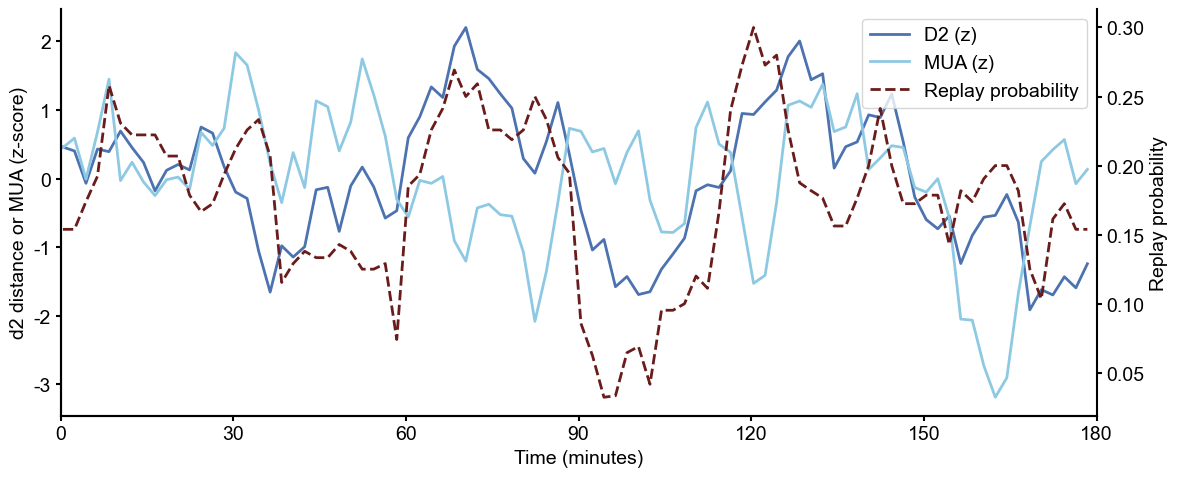

In [24]:
# Z-score within this window

import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
window_df["d2_z"]  = (window_df["d2"]  - window_df["d2"].mean())  / window_df["d2"].std()
window_df["MUA_z"] = (window_df["MUA"] - window_df["MUA"].mean()) / window_df["MUA"].std()
# Convert to relative seconds instead of minutes
window_df["time_seconds"] = window_df["center_s"] - window_start

window_df["time_minutes"] = (window_df["center_s"] - window_start) / 60

# Color palette
c_d2 = "#4C72B0"
c_mua = "#8EC9E3"
c_rep = "#691C1B"

fig, ax1 = plt.subplots(figsize=(12, 5))

# --- Left axis: z(D2) and z(MUA) ---
l1, = ax1.plot(
    window_df["time_seconds"], window_df["d2_z"],
    linewidth=2, color=c_d2, alpha=1, label="D2 (z)"
)

l2, = ax1.plot(
    window_df["time_seconds"], window_df["MUA_z"],
    linewidth=2, color=c_mua, alpha=1, label="MUA (z)"
)

ax1.set_ylabel("d2 distance or MUA (z-score)")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(False)

# --- Right axis: Replay probability ---
ax2 = ax1.twinx()
l3, = ax2.plot(
    window_df["time_seconds"], window_df["replay_prob"],
    linewidth=2, color=c_rep, alpha=1, linestyle="--", label="Replay probability"
)

ax2.set_ylabel("Replay probability")
ax2.spines["top"].set_visible(False)
ax2.grid(False)

ax1.set_xlabel("Time (minutes)")
# Force x-axis ticks at 0, 30, 60, 90, 120, 150, 180 s
ax1.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax1.set_xlim(0, 180)
# --- Combined legend ---
ax1.legend([l1, l2, l3],
           ["D2 (z)", "MUA (z)", "Replay probability"],
           loc="upper right")

plt.tight_layout()
savepath = rf'D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig2_C_{animal_name}_{day}_D2_MUA_replay_probability_{selected_epoch_idx}.svg'
plt.savefig(savepath, format='svg', dpi=300)
plt.show()

